# Customer Segmentation & Churn Pattern Analytics in European Banking
## End-to-End Empirical Data Science and Machine Learning Analysis

**Dataset:** European Banking Churn Dataset (10,000 customers across France, Germany, Spain)
**Target:** `Exited` (0 = Retained, 1 = Churned)

In [4]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Project root
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.data_loader import load_data, validate_data, get_data_quality_report
from src.preprocessing import add_segment_features, prepare_train_test_data
from src.analysis import compute_overview_kpis, compute_specialized_kpis, generate_data_driven_insights
from src.segmentation import get_all_segmentations, get_high_value_archetypes
from src.model import train_models, evaluate_model, compare_and_select_best_model

print('All modules loaded successfully.')

All modules loaded successfully.


## 1. Data Ingestion & Quality Validation

In [5]:
data_path = ROOT_DIR / 'data' / 'bank_churn.csv'
df = load_data(data_path)
quality_summary = validate_data(df)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Total Missing Values: {quality_summary['missing_values']['total_missing']}")
print(f"Duplicate Customer IDs: {quality_summary['duplicate_records']['duplicate_customer_ids']}")
print(f"Target Distribution: {quality_summary['target_validation']['counts']}")
print(f"Overall Churn Rate: {quality_summary['target_validation']['churn_rate']*100:.2f}%")

quality_df = get_data_quality_report(df)
quality_df

Dataset Shape: 10000 rows, 14 columns
Total Missing Values: 0
Duplicate Customer IDs: 0
Target Distribution: {0: 7963, 1: 2037}
Overall Churn Rate: 20.37%


,Column,Data Type,Non-Null Count,Null Count,Null %,Unique Values,Sample Value
0,Year,int64,10000,0,0.0,1,2025
1,CustomerId,int64,10000,0,0.0,10000,15634602
2,Surname,str,10000,0,0.0,2932,Hargrave
3,CreditScore,int64,10000,0,0.0,460,619
4,Geography,str,10000,0,0.0,3,France
5,Gender,str,10000,0,0.0,2,Female
6,Age,int64,10000,0,0.0,70,42
7,Tenure,int64,10000,0,0.0,11,2
8,Balance,float64,10000,0,0.0,6382,0.0
9,NumOfProducts,int64,10000,0,0.0,4,1


## 2. Statistical Analysis & Executive KPIs

In [6]:
kpis = compute_overview_kpis(df)
specialized = compute_specialized_kpis(df)

print('=== EXECUTIVE KPIS ===')
for k, v in kpis.items():
    print(f"{k:25}: {v}")

print('\n=== SPECIALIZED KPIS ===')
print(f"Engagement Drop Indicator (EDI): {specialized['engagement_drop_indicator']['edi_multiplier']}x")
print(f"Active Churn Rate: {specialized['engagement_drop_indicator']['active_churn_rate']}%")
print(f"Inactive Churn Rate: {specialized['engagement_drop_indicator']['inactive_churn_rate']}%")
print(f"High-Value Customer Churn Rate: {specialized['high_value']['high_value_churn_rate']}%")
print(f"High-Value Churn Contribution: {specialized['high_value']['high_value_contribution_ratio']}%")

=== EXECUTIVE KPIS ===
total_customers          : 10000
churned_customers        : 2037
retained_customers       : 7963
churn_rate               : 20.37
retention_rate           : 79.63
avg_age                  : 38.9
avg_credit_score         : 650.5
avg_balance              : 76485.89
total_balance            : 764858892.88
avg_tenure               : 5.0
avg_salary               : 100090.24

=== SPECIALIZED KPIS ===
Engagement Drop Indicator (EDI): 1.88x
Active Churn Rate: 14.27%
Inactive Churn Rate: 26.85%
High-Value Customer Churn Rate: 24.5%
High-Value Churn Contribution: 64.16%


## 3. Exploratory Data Analysis Visualizations

C:\Users\ashis\AppData\Local\Temp\ipykernel_23760\3135443372.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=geo_churn.index, y=geo_churn.values, ax=axes[0, 0], palette='Blues_d')
C:\Users\ashis\AppData\Local\Temp\ipykernel_23760\3135443372.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_churn.index, y=age_churn.values, ax=axes[0, 1], palette='Reds_d')
C:\Users\ashis\AppData\Local\Temp\ipykernel_23760\3135443372.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=prod_churn.index, y=prod_churn.values, ax=axes[0, 2], palet

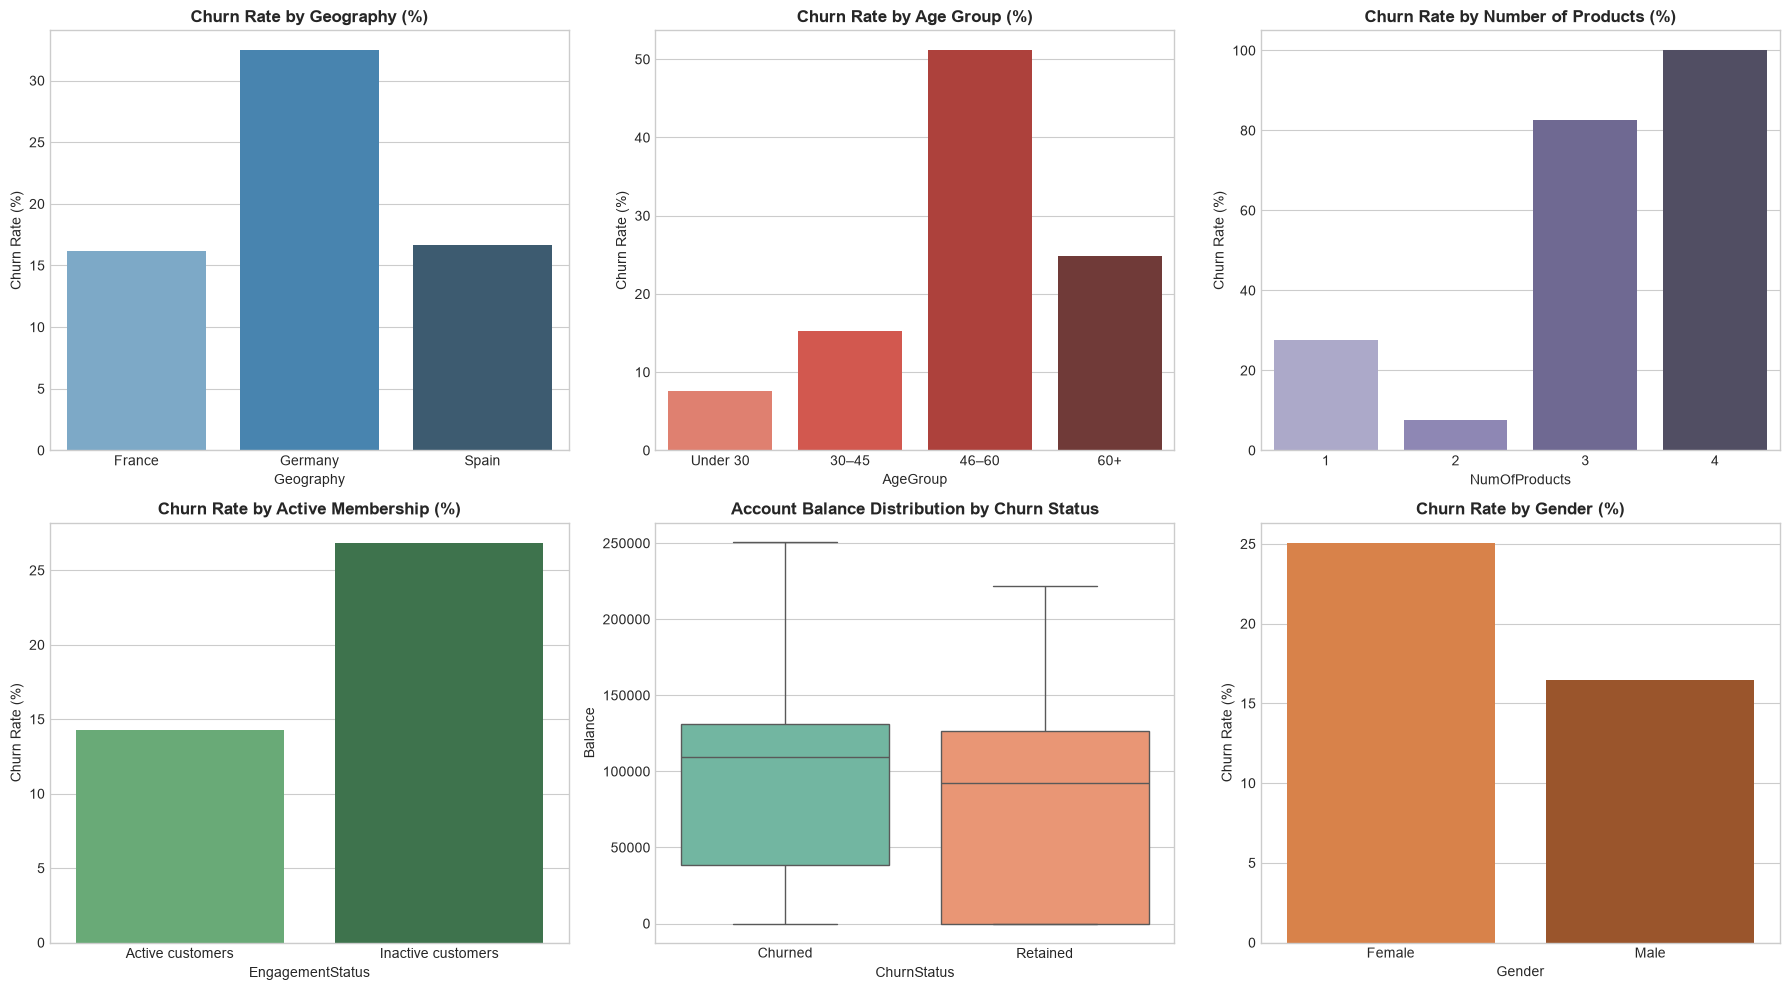

In [7]:
df_seg = add_segment_features(df)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Geography Churn Rate
geo_churn = df.groupby('Geography')['Exited'].mean() * 100
sns.barplot(x=geo_churn.index, y=geo_churn.values, ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('Churn Rate by Geography (%)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Churn Rate (%)')

# 2. Age Group Churn Rate
age_churn = df_seg.groupby('AgeGroup', observed=False)['Exited'].mean() * 100
sns.barplot(x=age_churn.index, y=age_churn.values, ax=axes[0, 1], palette='Reds_d')
axes[0, 1].set_title('Churn Rate by Age Group (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Churn Rate (%)')

# 3. Products Count Churn Rate
prod_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100
sns.barplot(x=prod_churn.index, y=prod_churn.values, ax=axes[0, 2], palette='Purples_d')
axes[0, 2].set_title('Churn Rate by Number of Products (%)', fontsize=12, fontweight='bold')
axes[0, 2].set_ylabel('Churn Rate (%)')

# 4. Active Membership
act_churn = df_seg.groupby('EngagementStatus')['Exited'].mean() * 100
sns.barplot(x=act_churn.index, y=act_churn.values, ax=axes[1, 0], palette='Greens_d')
axes[1, 0].set_title('Churn Rate by Active Membership (%)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Churn Rate (%)')

# 5. Balance Distribution by Churn Status
sns.boxplot(data=df_seg, x='ChurnStatus', y='Balance', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Account Balance Distribution by Churn Status', fontsize=12, fontweight='bold')

# 6. Gender Disparity
gender_churn = df.groupby('Gender')['Exited'].mean() * 100
sns.barplot(x=gender_churn.index, y=gender_churn.values, ax=axes[1, 2], palette='Oranges_d')
axes[1, 2].set_title('Churn Rate by Gender (%)', fontsize=12, fontweight='bold')
axes[1, 2].set_ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()

## 4. Customer Segmentation & Cohort Profiling

In [8]:
all_segs = get_all_segmentations(df)
print('=== GEOGRAPHIC SEGMENTS ===')
print(all_segs['Geography'])

print('\n=== AGE GROUP SEGMENTS ===')
print(all_segs['Age Group'])

print('\n=== HIGH-VALUE ARCHETYPES ===')
archetypes = get_high_value_archetypes(df)
archetype_df = pd.DataFrame(archetypes).T
archetype_df

=== GEOGRAPHIC SEGMENTS ===
  Geography  Customer_Count  Churned_Count  Avg_Balance  Avg_Credit_Score  Avg_Age  Churn_Rate_Pct  Retention_Rate_Pct  Churn_Contribution_Pct
0    France            5014            810     62092.64             649.7     38.5           16.15               83.85                   39.76
1   Germany            2509            814    119730.12             651.5     39.8           32.44               67.56                   39.96
2     Spain            2477            413     61818.15             651.3     38.9           16.67               83.33                   20.27

=== AGE GROUP SEGMENTS ===
   AgeGroup  Customer_Count  Churned_Count  Avg_Balance  Avg_Credit_Score  Avg_Age  Churn_Rate_Pct  Retention_Rate_Pct  Churn_Contribution_Pct
0  Under 30            1641            124     73698.72             651.1     25.9            7.56               92.44                    6.09
1     30–45            6248            956     75951.26             651.1     37.0    

,customer_count,churned_count,churn_rate,average_balance,total_balance_at_risk
Premier Depositors (Balance > $120k),3181.0,765.0,24.05,143651.31,1.100840e+08
Multi-Product Investors (2+ Products & >$50k),2178.0,457.0,20.98,120652.34,5.556347e+07
Senior Wealth Accounts (Age >= 50 & >$100k),708.0,371.0,52.40,131577.98,4.869699e+07
Prime Credit Active (Credit >= 750 & Active),843.0,112.0,13.29,79382.03,1.060352e+07


## 5. Machine Learning Modeling & Comparative Evaluation

In [9]:
split_data = prepare_train_test_data(df, test_size=0.2, random_state=42)
X_train = split_data['X_train']
X_test = split_data['X_test']
y_train = split_data['y_train']
y_test = split_data['y_test']
feature_names = split_data['feature_names']

# Train models
models = train_models(X_train, y_train, random_state=42)

evaluations = {}
for name, model in models.items():
    evaluations[name] = evaluate_model(model, X_test, y_test, feature_names)

best_model_name, comparison_df = compare_and_select_best_model(evaluations, primary_metric='ROC-AUC')
print(f"Best Performing Model: {best_model_name}")
comparison_df

Best Performing Model: Random Forest


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Random Forest,0.8225,0.5480,0.7297,0.6259,0.8647
0,Logistic Regression,0.7135,0.3872,0.7002,0.4987,0.7771


## 6. Confusion Matrix & Feature Importance

C:\Users\ashis\AppData\Local\Temp\ipykernel_23760\3931010918.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', ax=axes[1], palette='viridis')


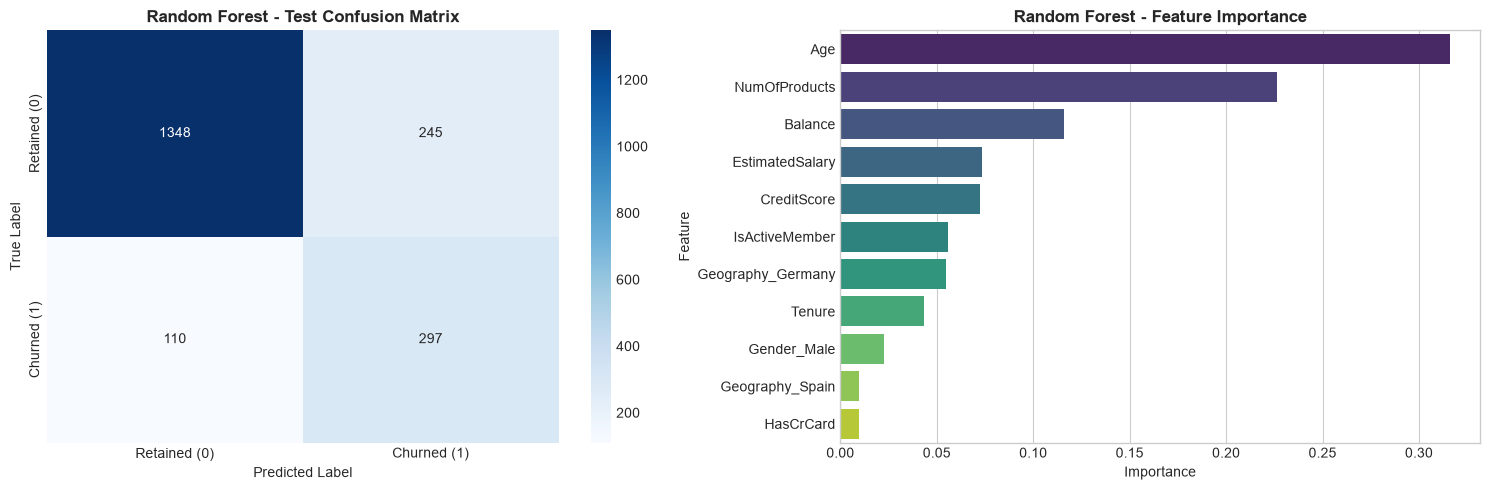

In [10]:
rf_eval = evaluations['Random Forest']
cm = np.array(rf_eval['confusion_matrix'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'])
axes[0].set_title('Random Forest - Test Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Feature Importance
feat_df = pd.DataFrame(rf_eval['feature_importance'])
sns.barplot(data=feat_df, x='Importance', y='Feature', ax=axes[1], palette='viridis')
axes[1].set_title('Random Forest - Feature Importance', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 7. Automated Data-Driven Insights

In [11]:
insights = generate_data_driven_insights(df)
for idx, ins in enumerate(insights, 1):
    print(f"{idx}. [{ins['category']}] {ins['title']}")
    print(f"   Finding: {ins['description']}")
    print(f"   Recommendation: {ins['recommendation']}\n")

1. [Geographic Disparity] High Churn Vulnerability in Germany
   Finding: Germany exhibits a churn rate of 32.4%, which is significantly higher than France (16.2%) and the benchmark average of 20.4%.
   Recommendation: Initiate local customer service reviews and tailored localized banking products in Germany.

2. [Demographics (Age)] Mature Demographic (46-60) Exhibits Peak Attrition
   Finding: Customers aged 46-60 face the steepest churn rate at 51.1%. In contrast, younger customers under 30 churn at 7.5%.
   Recommendation: Design wealth preservation, pension advisory, and senior relationship management initiatives.

3. [Product Cross-Selling] Severe Attrition in Over-Bundled Customers (3+ Products)
   Finding: Customers holding 3 or 4 banking products have a critical churn rate of 85.9% (spanning 326 accounts). Meanwhile, 2-product customers demonstrate the lowest attrition at 7.6%.
   Recommendation: Investigate friction, fee stacking, or product mismatch among multi-product accou